# Mechanics 5: Lagrangian mechanics

*Learning path: mechanics, part 5 of 7.* [Index](README.md) · Previous: [Gravity and orbits](04-gravity-and-orbits.ipynb) · Next: [Hamiltonian mechanics and phase space](06-hamiltonian-mechanics.ipynb)

Hang a second pendulum from the bob of a first one and let go. The lower arm whips around, flips over the top, pauses,
reverses: no two runs look alike. Writing Newton's laws for it means tracking the tension in both rods, which change
all the time and which nobody cares about. In 1788 Lagrange published a way around that: write down one number, the
kinetic minus the potential energy, in whatever coordinates suit the problem, and the equations of motion follow by
differentiation. Behind it is a strange and beautiful idea: of all the paths a system could take, it takes the one
that makes a certain quantity, the **action**, stationary.

**Who this is for.** You have done [lesson 4](04-gravity-and-orbits.ipynb) and are at ease with partial derivatives.

**What you will be able to do afterwards:**

1. state the principle of least action and test it on a thrown ball;
2. derive the Euler–Lagrange equations for a system and solve them for the accelerations;
3. simulate the double pendulum and see its chaos.

Plan about two hours.

## 1. The principle of least action

For a path $y(t)$ between two fixed events, define the **Lagrangian** $L = T - V$, kinetic minus potential energy, and
the **action** $S = \int L\,dt$. The principle: the path actually taken makes $S$ stationary (usually a minimum) among
all paths with the same start and end.

Test it on a ball thrown up at $t = 0$ from height 0 that lands back at height 0 at $t = 1$. Per unit mass,
$L = \tfrac12\dot y^2 - gy$. Try every parabola through both ends, $y = ct(1-t)$, and compute the action as a function
of $c$:

In [1]:
y = c*t*(1 - t);
A = integrate(diff(y, t)^2/2 - g*y, t, 0, 1)
solve(diff(A, c) == 0, c)

c*(c-g)/6

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

g/2

> Linear: c = −b/a = `g/2`.

The best parabola has $c = g/2$, so $y = \tfrac12gt(1-t)$, which is exactly what Newton gives
($\ddot y = -g$). Now bend the true path by any amount $h$ of a wiggle $\sin\pi t$ that vanishes at both ends:

In [2]:
y = g*t*(1 - t)/2 + h*sin(pi*t);
S1 = expand(integrate(diff(y, t)^2/2 - g*y, t, 0, 1))

pi^2*h^2/4-g^2/24

> `expand`: Multiplies out products and powers.

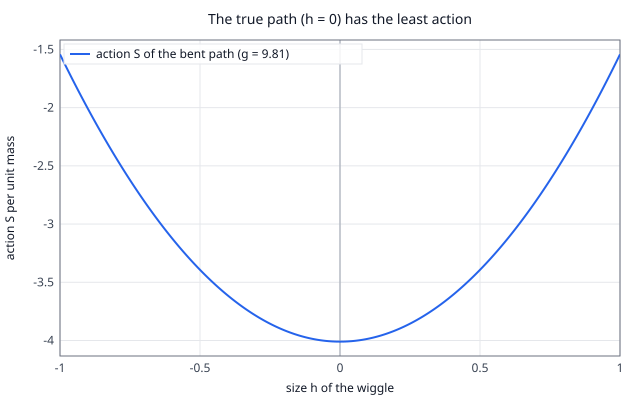

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
p = plot(pi^2*h^2/4 - 9.81^2/24, h, -1, 1);
p = legend(p, "action S of the bent path (g = 9.81)");
labels(title(p, "The true path (h = 0) has the least action"), "size h of the wiggle", "action S per unit mass")

The action grows as $h^2$ in either direction: the true path is the minimum, and to first order in $h$ the action does
not change at all. That "first-order change is zero" is the content of the principle.

**Try this.** Use the wiggle $\sin 2\pi t$ instead. Is $h = 0$ still the minimum?

## 2. The Euler–Lagrange equation

Making $\int L(q, \dot q)\,dt$ stationary over all paths gives, by the calculus of variations, one equation per
coordinate $q$:

$$\frac{d}{dt}\frac{\partial L}{\partial \dot q} - \frac{\partial L}{\partial q} = 0.$$

The coordinates can be anything: angles, distances along a wire, positions in a rotating frame. Galileo
differentiates with respect to symbols, so call the angle `th`, its rate `w` and its acceleration `a`. The time
derivative of a function of `th` and `w` is then, by the chain rule, $\partial_\theta F\cdot w + \partial_w F\cdot a$.
For a pendulum of length $l$, with the angle $\theta$ measured from straight down:

In [4]:
L = m*l^2*w^2/2 + m*g*l*cos(th);
dt(F) := diff(F, th)*w + diff(F, w)*a;
EL = dt(diff(L, w)) - diff(L, th)
solve(EL == 0, a)

a*l^2*m+g*l*m*sin(th)

-g*sin(th)/l

> Linear: a = −b/a = `-g*sin(th)/l`.

$\ddot\theta = -(g/l)\sin\theta$, the pendulum equation, without ever mentioning the tension in the string. Lagrange's
method throws away the forces that do no work (constraint forces) by choosing coordinates that respect the
constraints.

**Try this.** A bead slides on a frictionless wire bent into the parabola $y = x^2$. With $x$ as the coordinate,
$T = \tfrac12m(1 + 4x^2)\dot x^2$ and $V = mgx^2$. Find $\ddot x$.

## 3. The double pendulum

Two rods of lengths $l_1, l_2$ with masses $m_1, m_2$ at their ends; angles $q_1, q_2$ from straight down. The second
mass sits at $(l_1\sin q_1 + l_2\sin q_2,\ -l_1\cos q_1 - l_2\cos q_2)$; squaring its velocity gives the kinetic
energy below (exercise 2).

In [5]:
T = (m1 + m2)/2*l1^2*w1^2 + m2/2*l2^2*w2^2 + m2*l1*l2*w1*w2*cos(q1 - q2);
V = -(m1 + m2)*g*l1*cos(q1) - m2*g*l2*cos(q2);
L = T - V;
dt(F) := diff(F, q1)*w1 + diff(F, q2)*w2 + diff(F, w1)*a1 + diff(F, w2)*a2;
E1 = simplify(dt(diff(L, w1)) - diff(L, q1))
E2 = simplify(dt(diff(L, w2)) - diff(L, q2))

l1*(a1*l1*m1+a1*l1*m2+a2*l2*m2*cos(q1-q2)+g*m1*sin(q1)+g*m2*sin(q1)+l2*m2*w2^2*sin(q1-q2))

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

l2*m2*(a1*l1*cos(q1-q2)+a2*l2+g*sin(q2)-l1*w1^2*sin(q1-q2))

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

Two equations, linear in the accelerations $a_1, a_2$. Solve for them:

In [6]:
s = solve([E1 == 0, E2 == 0], [a1 a2])

[(g*m2*sin(q2)*cos(q1-q2)-g*m1*sin(q1)-g*m2*sin(q1)-l1*m2*w1^2*sin(q1-q2)*cos(q1-q2)-l2*m2*w2^2*sin(q1-q2))/(l1*(m1+m2*sin(q1-q2)^2)), (m1+m2)*(l2*m2*cos(q1-q2)*(g*m1*sin(q1)+g*m2*sin(q1)+l2*m2*w2^2*sin(q1-q2))/(m1+m2)+l2*m2*(l1*w1^2*sin(q1-q2)-g*sin(q2)))/(l2^2*m2*(m1+m2*sin(q1-q2)^2))]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

Nobody would want to get that right by drawing forces. Now take equal masses and 1 m rods, and start with both arms
high up, at 2 and 2.5 radians from the bottom:

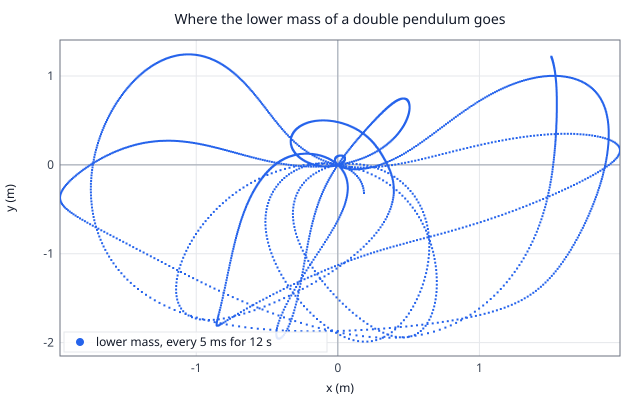

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
m1 = 1; m2 = 1; l1 = 1; l2 = 1; g = 9.81;
f = eval(s);
D = odedata([w1, w2, f(1), f(2)], [q1 q2 w1 w2], t, [2, 2.5, 0, 0], 0, 12, 2400);
p = scatter(D, [t q1 q2 w1 w2], [sin(q1) + sin(q2), -cos(q1) - cos(q2)]);
p = legend(p, "lower mass, every 5 ms for 12 s");
labels(title(p, "Where the lower mass of a double pendulum goes"), "x (m)", "y (m)")

Energy must stay constant, since no force does net work besides gravity. Check it at a few moments:

In [8]:
En(k) := eval(subs(subs(subs(subs(T + V, q1, D(k, 2)), q2, D(k, 3)), w1, D(k, 4)), w2, D(k, 5)), 6);
[En(1), En(800), En(1600), En(2401)]

[16.0240, 16.0240, 16.0240, 16.0240]

## 4. Chaos

Run it again with the upper arm started one thousandth of a radian higher, and follow the angle of the lower arm:

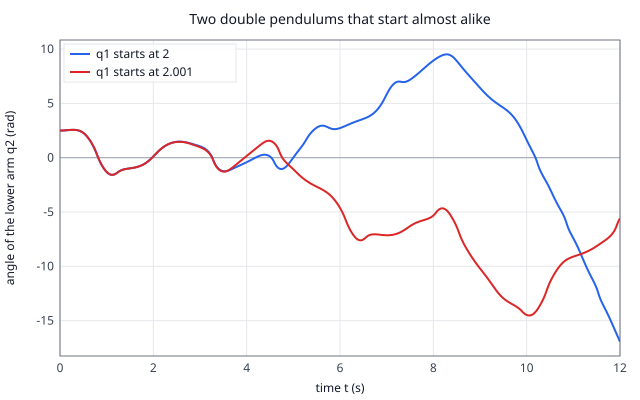

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
p = odeplot([w1, w2, f(1), f(2)], [q1 q2 w1 w2], t, [2, 2.5, 0, 0], 0, 12, [t q2]);
p = show(p, odeplot([w1, w2, f(1), f(2)], [q1 q2 w1 w2], t, [2.001, 2.5, 0, 0], 0, 12, [t q2]));
p = legend(p, "q1 starts at 2", "q1 starts at 2.001");
labels(title(p, "Two double pendulums that start almost alike"), "time t (s)", "angle of the lower arm q2 (rad)")

For a few seconds the curves agree; then they separate completely. Each time the lower arm flips over the top, its
angle jumps by $2\pi$ for good. This is the same **sensitive dependence** as in the three-body problem of lesson 4. With
small swings the double pendulum is perfectly tame: it moves in two **normal modes**, the subject of
[Oscillations and waves 2](../waves/02-coupled-oscillators.ipynb).

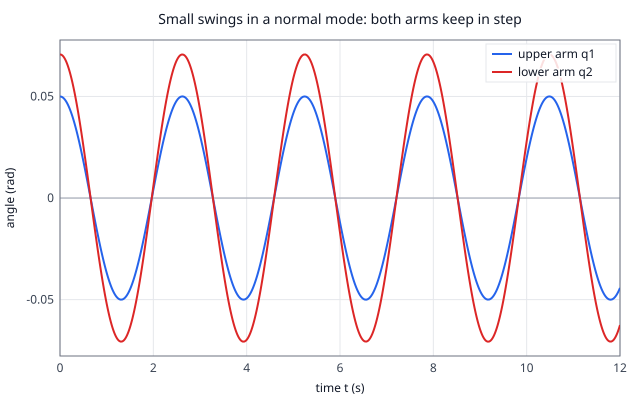

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
small = [0.05, 0.05*sqrt(2), 0, 0];
p = odeplot([w1, w2, f(1), f(2)], [q1 q2 w1 w2], t, small, 0, 12, [t q1]);
p = show(p, odeplot([w1, w2, f(1), f(2)], [q1 q2 w1 w2], t, small, 0, 12, [t q2]));
p = legend(p, "upper arm q1", "lower arm q2");
labels(title(p, "Small swings in a normal mode: both arms keep in step"), "time t (s)", "angle (rad)")

Started with $q_2 = \sqrt2\,q_1$, both arms swing at one frequency forever, the lower arm $\sqrt2$ times as far: a
normal mode.

**Try this.** Start at $q_1 = 0.05$, $q_2 = -0.05\sqrt2$. What happens to the period?

## Summary

* The path a system takes makes the action $S = \int (T - V)\,dt$ stationary.
* That gives one Euler–Lagrange equation per coordinate,
  $\frac{d}{dt}\partial L/\partial\dot q = \partial L/\partial q$, in any coordinates; constraint forces never appear.
* The double pendulum's equations come out in a few lines; its motion at large swings is chaotic, at small swings a sum
  of two normal modes.

Next: [Hamiltonian mechanics and phase space](06-hamiltonian-mechanics.ipynb), where symmetries become conservation
laws.

## Exercises

1. **Spring.** Write $L$ for a mass on a spring ($V = \tfrac12kx^2$) and derive the equation of motion.
2. **Double pendulum energy.** Differentiate the position of the lower mass and check the kinetic energy $T$ used in
   section 3.
3. **Polar coordinates.** For a particle in a plane with $V(r)$, $L = \tfrac12m(\dot r^2 + r^2\dot\theta^2) - V(r)$.
   Derive both equations. Which one says that $mr^2\dot\theta$ is constant?
4. **Atwood machine.** Masses $m_1$ and $m_2$ hang over a pulley on one string. With $x$ the drop of $m_1$, write $L$
   and find the acceleration.
5. **Longer chaos.** In section 4, how long do the two runs agree if the difference is $10^{-6}$ instead of $10^{-3}$?
6. **Pendulum on a cart.** A pendulum hangs from a cart of mass $M$ that slides freely along $x$. Write $L$ in terms of
   $x$ and $\theta$ and derive the two equations.

## Hints and answers

* **Section 1, Try this.** Yes: the action becomes $S_0 + \pi^2h^2$, again smallest at $h = 0$.
* **Section 2, Try this.** $\ddot x = -2x(g + 2\dot x^2)/(1 + 4x^2)$.
* **Section 4, Try this.** The other normal mode: both arms swing in opposite directions with a shorter period
  ($\omega^2 = (2+\sqrt2)g/l$ against $(2-\sqrt2)g/l$).
* **Exercise 1.** $m\ddot x = -kx$.
* **Exercise 2.** $v^2 = l_1^2\dot q_1^2 + l_2^2\dot q_2^2 + 2l_1l_2\dot q_1\dot q_2\cos(q_1 - q_2)$, and the upper
  mass contributes $\tfrac12m_1l_1^2\dot q_1^2$.
* **Exercise 3.** The $\theta$ equation is $\frac{d}{dt}(mr^2\dot\theta) = 0$, because $L$ does not contain $\theta$.
* **Exercise 4.** $L = \tfrac12(m_1 + m_2)\dot x^2 + (m_1 - m_2)gx$, so $\ddot x = (m_1 - m_2)g/(m_1 + m_2)$.
* **Exercise 5.** Roughly twice as long: the gap grows exponentially, so each factor of 1000 buys the same extra time.
* **Exercise 6.** $L = \tfrac12(M + m)\dot x^2 + ml\dot x\dot\theta\cos\theta + \tfrac12ml^2\dot\theta^2 + mgl\cos\theta$.

## Sources

1. J.-L. Lagrange, *Mécanique analytique* (1788).
2. W. R. Hamilton, "On a general method in dynamics", *Philosophical Transactions of the Royal Society* 124, 247–308
   (1834).
3. R. P. Feynman, R. B. Leighton and M. Sands, *The Feynman Lectures on Physics*, vol. II, chapter 19 ("The principle
   of least action"), Addison-Wesley (1964).
4. T. Shinbrot, C. Grebogi, J. Wisdom and J. A. Yorke, "Chaotic dynamics of a double pendulum", *American Journal of
   Physics* 60, 491–499 (1992).